# ch8

### config

In [27]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

from joblib import Parallel, delayed

import matplotlib.pyplot as plt
import seaborn as sns


### 8.1. 패널데이터

In [2]:
mkt_data = (pd.read_csv("../../data/short_offline_mkt_south.csv")
            .astype({"date":"datetime64[ns]"}))

mkt_data.head()

,date,city,region,treated,tau,downloads,post
0,2021-05-01,5,S,0,0.0,51.0,0
1,2021-05-02,5,S,0,0.0,51.0,0
2,2021-05-03,5,S,0,0.0,51.0,0
3,2021-05-04,5,S,0,0.0,50.0,0
4,2021-05-05,5,S,0,0.0,49.0,0


In [3]:
(mkt_data
 .assign(w = lambda d: d["treated"]*d["post"])
 .groupby(["w"])
 .agg({"date":[min, max]}))

/var/folders/7p/2d8wttz900j688bhp1zy67j40000gn/T/ipykernel_69501/2583971365.py:4: FutureWarning: The provided callable <built-in function min> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  .agg({"date":[min, max]}))
/var/folders/7p/2d8wttz900j688bhp1zy67j40000gn/T/ipykernel_69501/2583971365.py:4: FutureWarning: The provided callable <built-in function max> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  .agg({"date":[min, max]}))


date           
         min        max
w                      
0 2021-05-01 2021-06-01
1 2021-05-15 2021-06-01

### 8.2. 표준 이중차분법

In [5]:
did_data = (mkt_data
            .groupby(["treated", "post"])
            .agg({"downloads":"mean", "date": "min"}))

did_data

downloads       date
treated post                      
0       0     50.335034 2021-05-01
        1     50.556878 2021-05-15
1       0     50.944444 2021-05-01
        1     51.858025 2021-05-15

In [6]:
y0_est = (did_data.loc[1].loc[0, "downloads"] # 실험군 기준값
          + did_data.loc[0].diff().loc[1, "downloads"]) # 대조군 추세

att = did_data.loc[1].loc[1, "downloads"] - y0_est
att

np.float64(0.6917359536407233)

In [8]:
mkt_data.query("post==1").query("treated==1")["tau"].mean()

np.float64(0.7660316402518457)

In [9]:
pre = mkt_data.query("post==0").groupby("city")["downloads"].mean()
post = mkt_data.query("post==1").groupby("city")["downloads"].mean()

delta_y = ((post - pre).rename("delta_y").to_frame()
           # 처치 더미변수를 추가
           .join(mkt_data.groupby("city")["treated"].max()))

delta_y.tail()

,delta_y,treated
city,,
192,0.555556,0
193,0.166667,0
195,0.420635,0
196,0.119048,0
197,1.595238,1


In [10]:
(delta_y.query("treated==1")["delta_y"].mean() 
 - delta_y.query("treated==0")["delta_y"].mean())

np.float64(0.6917359536407155)

In [11]:
# 이중차분법과 ols
did_data = (mkt_data
            .groupby(["city", "post"])
            .agg({"downloads":"mean", "date": "min", "treated": "max"})
            .reset_index())

did_data.head()

,city,post,downloads,date,treated
0,5,0,50.642857,2021-05-01,0
1,5,1,50.166667,2021-05-15,0
2,15,0,49.142857,2021-05-01,0
3,15,1,49.166667,2021-05-15,0
4,20,0,48.785714,2021-05-01,0


In [13]:
smf.ols(
    'downloads ~ treated*post', data=did_data
).fit().params["treated:post"]

np.float64(0.6917359536407282)

In [14]:
# 이중차분법과 고정효과
m = smf.ols('downloads ~ treated:post + C(city) + C(post)',
            data=did_data).fit()

m.params["treated:post"]

np.float64(0.6917359536407496)

In [15]:
# 이중차분법과 블록 디자인
m = smf.ols('downloads ~ treated*post', data=mkt_data).fit()

m.params["treated:post"]

np.float64(0.6917359536406944)

In [16]:
m = smf.ols('downloads ~ treated:post + C(city) + C(date)',
            data=mkt_data).fit()

m.params["treated:post"]

np.float64(0.6917359536407054)

In [17]:
# 추론

m = smf.ols('downloads ~ treated:post + C(city) + C(date)', data=mkt_data
            ).fit(cov_type='cluster', cov_kwds={'groups': mkt_data['city']})

print("ATT:", m.params["treated:post"])
m.conf_int().loc["treated:post"]

ATT: 0.6917359536407054


0    0.296101
1    1.087370
Name: treated:post, dtype: float64

In [18]:
m = smf.ols('downloads ~ treated:post + C(city) + C(date)',
            data=mkt_data).fit()

print("ATT:", m.params["treated:post"])
m.conf_int().loc["treated:post"]

ATT: 0.6917359536407054


0    0.478014
1    0.905457
Name: treated:post, dtype: float64

In [19]:
m = smf.ols(
    'downloads ~ treated:post + C(city) + C(date)', data=did_data
).fit(cov_type='cluster', cov_kwds={'groups': did_data['city']})

print("ATT:", m.params["treated:post"])
m.conf_int().loc["treated:post"]

ATT: 0.6917359536407496


0    0.138188
1    1.245284
Name: treated:post, dtype: float64

In [21]:
# 블록 부트스트랩 구현

def block_sample(df, unit_col):
    
    units = df[unit_col].unique()
    sample = np.random.choice(units, size=len(units), replace=True) 
    
    return (df
            .set_index(unit_col)
            .loc[sample]
            .reset_index(level=[unit_col]))

def block_bootstrap(data, est_fn, unit_col,
                    rounds=200, seed=123, pcts=[2.5, 97.5]):
    np.random.seed(seed)
    
    stats = Parallel(n_jobs=4)(
        delayed(est_fn)(block_sample(data, unit_col=unit_col))
        for _ in range(rounds))
    
    return np.percentile(stats, pcts)


def est_fn(df):
    m = smf.ols('downloads ~ treated:post + C(city) + C(date)',
                data=df).fit()
    return m.params["treated:post"]

In [22]:
block_bootstrap(mkt_data, est_fn, "city")

array([0.23162214, 1.14002646])

### 8.3. 식별 가정

### 8.4. 시간에 따른 효과 변동

In [23]:
def did_date(df, date):
    df_date = (df
               .query("date==@date | post==0")
               .query("date <= @date")
               .assign(post = lambda d: (d["date"]==date).astype(int)))
    
    m = smf.ols(
        'downloads ~ I(treated*post) + C(city) + C(date)', data=df_date
    ).fit(cov_type='cluster', cov_kwds={'groups': df_date['city']})
    
    att = m.params["I(treated * post)"]
    ci = m.conf_int().loc["I(treated * post)"]
    
    return pd.DataFrame({"att": att, "ci_low": ci[0], "ci_up": ci[1]}, index=[date])

In [25]:
post_dates = sorted(mkt_data["date"].unique())[1:]
atts = pd.concat([did_date(mkt_data, date) for date in post_dates])

atts.head()

,att,ci_low,ci_up
2021-05-02,0.325397,-0.491741,1.142534
2021-05-03,0.384921,-0.388389,1.158231
2021-05-04,-0.156085,-1.247491,0.935321
2021-05-05,-0.299603,-0.949935,0.350729
2021-05-06,0.347619,0.013115,0.682123


### 8.5. 이중차분법과 공변량

In [26]:
mkt_data_all = (pd.read_csv("../../data/short_offline_mkt_all_regions.csv")
                .astype({"date":"datetime64[ns]"}))

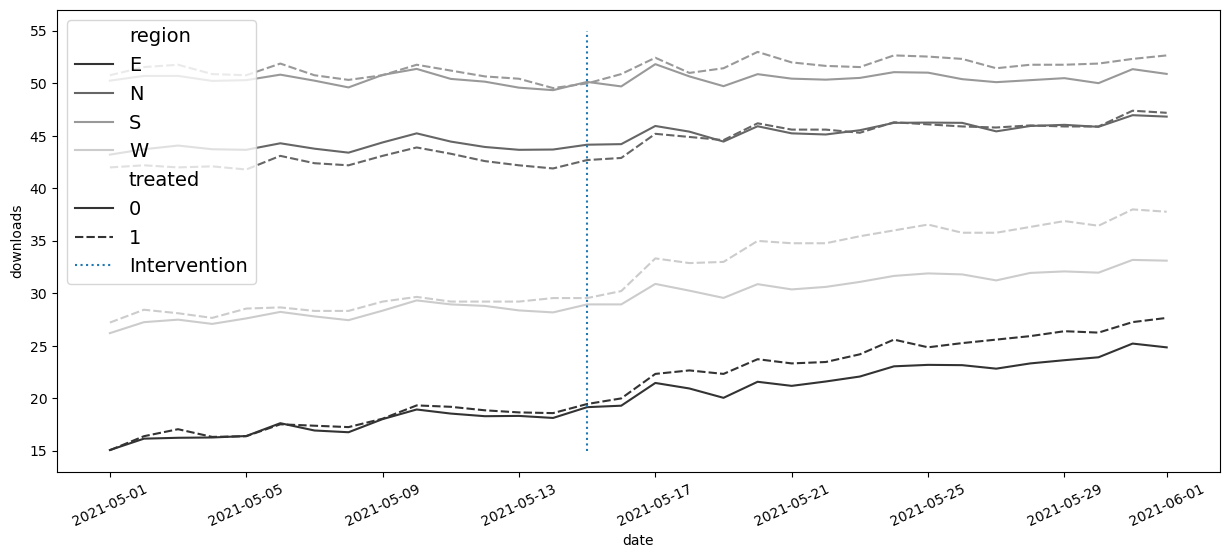

In [28]:
plt.figure(figsize=(15,6))
sns.lineplot(data=mkt_data_all.groupby(["date", "region", "treated"])[["downloads"]].mean().reset_index(),
             x="date", y="downloads", hue="region", style="treated", palette="gray")

plt.vlines(pd.to_datetime("2021-05-15"), 15, 55, ls="dotted", label="Intervention")
plt.legend(fontsize=14)

plt.xticks(rotation=25);

In [29]:
print("True ATT: ", mkt_data_all.query("treated*post==1")["tau"].mean())

m = smf.ols('downloads ~ treated:post + C(city) + C(date)',
            data=mkt_data_all).fit()

print("Estimated ATT:", m.params["treated:post"])

True ATT:  1.7208921056102682
Estimated ATT: 2.0683919842564005


In [30]:
m = smf.ols('downloads ~ treated:post + C(city) + C(date) + C(region)',
            data=mkt_data_all).fit()
m.params["treated:post"] 

np.float64(2.06847211722299)

In [31]:
m_saturated = smf.ols('downloads ~ (post*treated)*C(region)',
                      data=mkt_data_all).fit()

atts = m_saturated.params[m_saturated.params.index.str.contains("post:treated")]
atts

post:treated                   1.676808
post:treated:C(region)[T.N]   -0.343667
post:treated:C(region)[T.S]   -0.985072
post:treated:C(region)[T.W]    1.369363
dtype: float64

In [32]:
reg_size = (mkt_data_all.groupby("region").size()
            /len(mkt_data_all["date"].unique()))

base = atts[0]

np.array([reg_size[0]*base]+
         [(att+base)*size
          for att, size in zip(atts[1:], reg_size[1:])]
        ).sum()/sum(reg_size)

/var/folders/7p/2d8wttz900j688bhp1zy67j40000gn/T/ipykernel_69501/423212460.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  base = atts[0]
/var/folders/7p/2d8wttz900j688bhp1zy67j40000gn/T/ipykernel_69501/423212460.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  np.array([reg_size[0]*base]+


np.float64(1.6940400451471702)

In [33]:
m = smf.ols('downloads ~ post*(treated + C(region))',
            data=mkt_data_all).fit()

m.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,17.3522,0.101,172.218,0.000,17.155,17.550
C(region)[T.N],26.2770,0.137,191.739,0.000,26.008,26.546
C(region)[T.S],33.0815,0.135,245.772,0.000,32.818,33.345
C(region)[T.W],10.7118,0.135,79.581,0.000,10.448,10.976
post,4.9807,0.134,37.074,0.000,4.717,5.244
post:C(region)[T.N],-3.3458,0.183,-18.310,0.000,-3.704,-2.988
post:C(region)[T.S],-4.9334,0.179,-27.489,0.000,-5.285,-4.582
post:C(region)[T.W],-1.5408,0.179,-8.585,0.000,-1.893,-1.189
treated,0.0503,0.117,0.429,0.668,-0.179,0.280
post:treated,1.6811,0.156,10.758,0.000,1.375,1.987


### 8.6. 이중 강건 이중차분법

In [34]:
# 성향점수 모델

unit_df = (mkt_data_all
           # 첫 번째 날짜 유지
           .astype({"date": str})
           .query(f"date=='{mkt_data_all['date'].astype(str).min()}'")
           .drop(columns=["date"])) # just to avoid confusion

ps_model = smf.logit("treated~C(region)", data=unit_df).fit(disp=0)

In [37]:
# 델타 결과 모델

delta_y = (
    mkt_data_all.query("post==1").groupby("city")["downloads"].mean()
    - mkt_data_all.query("post==0").groupby("city")["downloads"].mean())

df_delta_y = (unit_df
              .set_index("city")
              .join(delta_y.rename("delta_y")))

outcome_model = smf.ols("delta_y ~ C(region)", data=df_delta_y).fit()

In [38]:
# 최종 결과

df_dr = (df_delta_y
         .assign(y_hat = lambda d: outcome_model.predict(d))
         .assign(ps = lambda d: ps_model.predict(d)))

df_dr.head()

,region,treated,tau,downloads,post,delta_y,y_hat,ps
city,,,,,,,,
1,W,0,0.0,27.0,0,3.087302,3.736539,0.176471
2,N,0,0.0,40.0,0,1.436508,1.992570,0.212766
3,W,0,0.0,30.0,0,2.761905,3.736539,0.176471
4,W,0,0.0,26.0,0,3.396825,3.736539,0.176471
5,S,0,0.0,51.0,0,-0.476190,0.343915,0.176471


In [39]:
tr = df_dr.query("treated==1")
co = df_dr.query("treated==0")

dy1_treat = (tr["delta_y"] - tr["y_hat"]).mean()

w_cont = co["ps"]/(1-co["ps"])
dy0_treat = np.average(co["delta_y"] - co["y_hat"], weights=w_cont)

print("ATT:", dy1_treat - dy0_treat)

ATT: 1.6773180394442855


### 8.7. 처치의 시차 도입

In [40]:
mkt_data_cohorts = (pd.read_csv("../../data/offline_mkt_staggered.csv")
                    .astype({"date":"datetime64[ns]", "cohort":"datetime64[ns]"}))

mkt_data_cohorts.head()

,date,city,region,cohort,treated,tau,downloads,post
0,2021-05-01,1,W,2021-06-20,1,0.0,27.0,0
1,2021-05-02,1,W,2021-06-20,1,0.0,28.0,0
2,2021-05-03,1,W,2021-06-20,1,0.0,28.0,0
3,2021-05-04,1,W,2021-06-20,1,0.0,26.0,0
4,2021-05-05,1,W,2021-06-20,1,0.0,28.0,0


/var/folders/7p/2d8wttz900j688bhp1zy67j40000gn/T/ipykernel_69501/3753200403.py:6: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  .sort_values(list(sorted(mkt_data_cohorts.query("cohort!='2100-01-01'")["cohort"].astype("str").unique())), ascending=False)


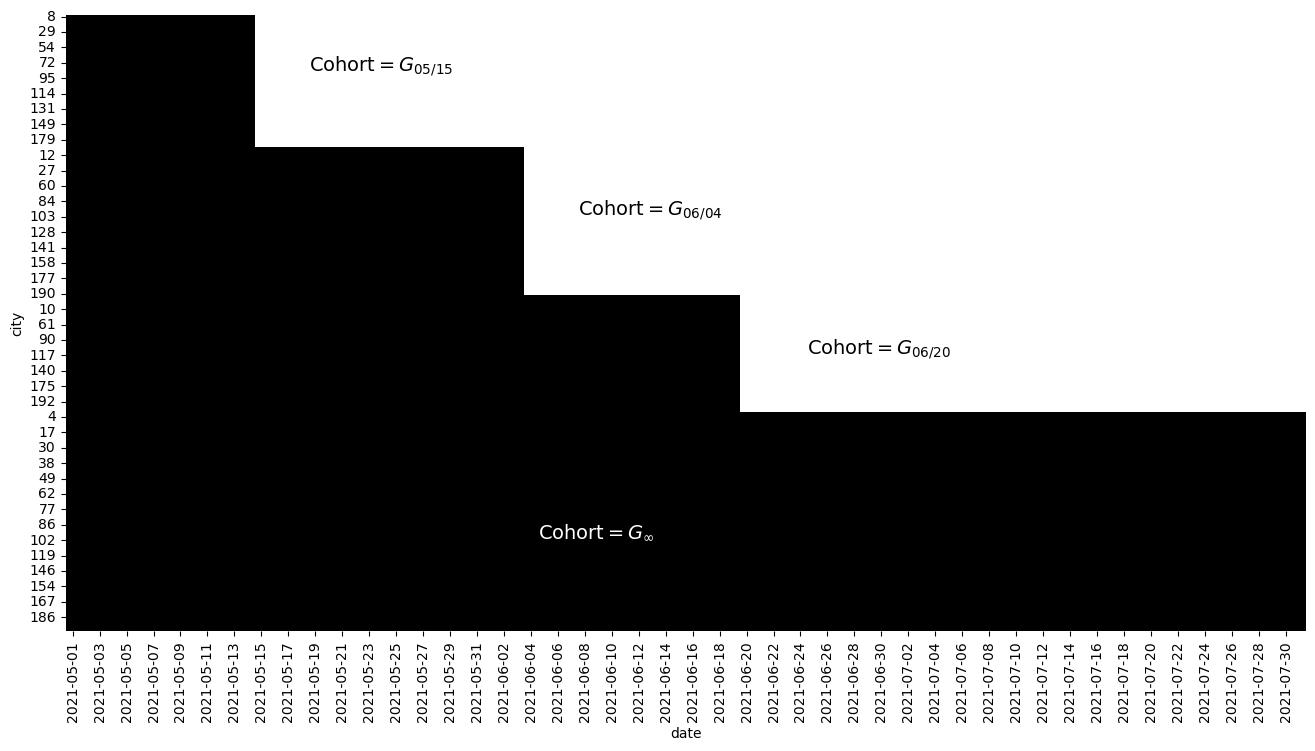

In [45]:
plt_data = (mkt_data_cohorts
            .astype({"date":"str"})
            .assign(treated_post = lambda d: d["treated"]*(d["date"]>=d["cohort"]))
            .pivot(index = "city", columns = "date", values = "treated_post")
            .reset_index()
            .sort_values(list(sorted(mkt_data_cohorts.query("cohort!='2100-01-01'")["cohort"].astype("str").unique())), ascending=False)
            .reset_index()
            .drop(columns=["city"])
            .rename(columns={"index":"city"})
            .set_index("city"))

plt.figure(figsize=(16,8))

sns.heatmap(plt_data, cmap="gray",cbar=False)
plt.text(18, 18, "Cohort$=G_{05/15}$", size=14)
plt.text(38, 65, "Cohort$=G_{06/04}$", size=14)
plt.text(55, 110, "Cohort$=G_{06/20}$", size=14)
plt.text(35, 170, "Cohort$=G_{\\infty}$", color="white", size=14, weight=3);

# 시차 도입 설계에서는 점점 더 많은 실험 대상이 점진적으로 처치를 받음

In [46]:
mkt_data_cohorts_w = mkt_data_cohorts.query("region=='W'")
mkt_data_cohorts_w.head()

,date,city,region,cohort,treated,tau,downloads,post
0,2021-05-01,1,W,2021-06-20,1,0.0,27.0,0
1,2021-05-02,1,W,2021-06-20,1,0.0,28.0,0
2,2021-05-03,1,W,2021-06-20,1,0.0,28.0,0
3,2021-05-04,1,W,2021-06-20,1,0.0,26.0,0
4,2021-05-05,1,W,2021-06-20,1,0.0,28.0,0


In [47]:
twfe_model = smf.ols(
    "downloads ~ treated:post + C(date) + C(city)",
    data=mkt_data_cohorts_w).fit()

true_tau = mkt_data_cohorts_w.query("post==1&treated==1")["tau"].mean()

print("True Effect: ", true_tau)
print("Estimated ATT:", twfe_model.params["treated:post"])

True Effect:  2.2625252108176266
Estimated ATT: 1.7599504780633812


In [48]:
# 시간에 따른 이질적 효과

formula = "downloads ~ treated:post:C(cohort):C(date) + C(city)+C(date)"

twfe_model = smf.ols(formula, data=mkt_data_cohorts_w).fit()

In [49]:
df_pred = (
    mkt_data_cohorts_w
    .query("post==1 & treated==1")
    .assign(y_hat_0=lambda d: twfe_model.predict(d.assign(treated=0)))
    .assign(effect_hat=lambda d: d["downloads"] - d["y_hat_0"])
)

print("Number of param.:", len(twfe_model.params))
print("True Effect: ", df_pred["tau"].mean())
print("Pred. Effect: ", df_pred["effect_hat"].mean())

Number of param.: 510
True Effect:  2.2625252108176266
Pred. Effect:  2.259766144685017


In [50]:
cohorts = sorted(mkt_data_cohorts_w["cohort"].unique())

treated_G = cohorts[:-1]
nvr_treated = cohorts[-1]

def did_g_vs_nvr_treated(df: pd.DataFrame,
                         cohort: str,
                         nvr_treated: str,
                         cohort_col: str = "cohort",
                         date_col: str = "date",
                         y_col: str = "downloads"):
    did_g = (df
        .loc[lambda d:(d[cohort_col] == cohort)|
                      (d[cohort_col] == nvr_treated)]
        .assign(treated = lambda d: (d[cohort_col] == cohort)*1)
        .assign(post = lambda d:(pd.to_datetime(d[date_col])>=cohort)*1))
    
    att_g = smf.ols(f"{y_col} ~ treated*post",
                    data=did_g).fit().params["treated:post"]
    size = len(did_g.query("treated==1 & post==1"))
    return {"att_g": att_g, "size": size}


atts = pd.DataFrame(
    [did_g_vs_nvr_treated(mkt_data_cohorts_w, cohort, nvr_treated)
     for cohort in treated_G])
    
atts

,att_g,size
0,3.455535,702
1,1.659068,1044
2,1.573687,420


In [51]:
(atts["att_g"]*atts["size"]).sum()/atts["size"].sum()

np.float64(2.224746774055892)

In [53]:
# 공변량

formula = """downloads ~ treated:post:C(cohort):C(date)
+ C(date):C(region) + C(city) + C(date)"""

twfe_model = smf.ols(formula, data=mkt_data_cohorts).fit()

In [54]:
df_pred = (mkt_data_cohorts
    .query("post==1 & treated==1")
    .assign(y_hat_0=lambda d: twfe_model.predict(d.assign(treated=0)))
    .assign(effect_hat=lambda d: d["downloads"] - d["y_hat_0"]))

print("Number of param.:", len(twfe_model.params))
print("True Effect: ",  df_pred["tau"].mean())
print("Pred. Effect: ", df_pred["effect_hat"].mean())

Number of param.: 935
True Effect:  2.078397729895905
Pred. Effect:  2.0472914404551235
